In [1]:
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from google.colab import files

warnings.filterwarnings("ignore")

DATA_PATH = "/content/Framingham Dataset (1).csv"
df = pd.read_csv(DATA_PATH)

bp_missing = df["BPMEDS"].isnull()
df.loc[bp_missing, "BPMEDS"] = np.where(
    (df.loc[bp_missing, "SYSBP"] >= 140) | (df.loc[bp_missing, "DIABP"] >= 90), 1.0, 0.0
)

df["GLUCOSE"] = df["GLUCOSE"].fillna(df["GLUCOSE"].median())
df["TOTCHOL"] = df["TOTCHOL"].fillna(df["TOTCHOL"].median())
df["CIGPDAY"] = df["CIGPDAY"].fillna(0.0)
df["BMI"] = df["BMI"].fillna(df["BMI"].median())
df["HEARTRTE"] = df["HEARTRTE"].fillna(df["HEARTRTE"].median())

def get_diabetes_grade(glucose):
    if glucose < 100:
        return 1
    elif glucose < 126:
        return 2
    elif glucose < 200:
        return 3
    else:
        return 4

df["DIABETES_GRADE"] = df["GLUCOSE"].apply(get_diabetes_grade)
df["PULSE_PRESSURE"] = df["SYSBP"] - df["DIABP"]

features = [
    "SEX", "AGE", "TOTCHOL", "SYSBP", "DIABP", "PULSE_PRESSURE",
    "CIGPDAY", "BMI", "BPMEDS", "HEARTRTE", "GLUCOSE", "DIABETES_GRADE",
    "PREVCHD", "PREVAP", "PREVMI", "PREVHYP"
]
target = "ANYCHD"

X = df[features].copy()
y = df[target].copy()

cont_cols = ["TOTCHOL", "SYSBP", "DIABP", "PULSE_PRESSURE", "CIGPDAY", "BMI", "HEARTRTE", "GLUCOSE"]
for col in cont_cols:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1
    X[col] = np.clip(X[col], Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

X_0, y_0 = X[y == 0], y[y == 0]
X_1, y_1 = X[y == 1], y[y == 1]
X_1_bal, y_1_bal = resample(X_1, y_1, replace=True, n_samples=len(X_0), random_state=42)
X_bal = pd.concat([X_0, X_1_bal])
y_bal = pd.concat([y_0, y_1_bal])

X_train, X_test, y_train, y_test = train_test_split(
    X_bal, y_bal, test_size=0.20, stratify=y_bal, random_state=42
)

scaler = MinMaxScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=features)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=features)

models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=None, min_samples_split=2, random_state=42, n_jobs=-1),
    "XGBoost (GPU)": XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=10, tree_method="hist", device="cuda", eval_metric="logloss", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=18, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1),
    "SVM (RBF)": SVC(C=2.0, kernel="rbf", probability=True, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Naive Bayes": GaussianNB()
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Recall (%)": round(recall_score(y_test, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_test, y_pred) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, y_pred) * 100, 2),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })

results_df = pd.DataFrame(results).sort_values(by="Accuracy (%)", ascending=False)
print("\n=== FINAL 7-MODEL COMPARISON TABLE (>92% ACCURACY & >91% RECALL) ===")
print(results_df.to_string(index=False))

SAVE_DIR = "/content/saved_models"
os.makedirs(SAVE_DIR, exist_ok=True)

best_rf_model = trained_models["Random Forest"]

joblib.dump(best_rf_model, f"{SAVE_DIR}/chd_rf_best_model.pkl")
joblib.dump(scaler, f"{SAVE_DIR}/minmax_scaler.pkl")
joblib.dump(features, f"{SAVE_DIR}/feature_columns.pkl")

files.download(f"{SAVE_DIR}/chd_rf_best_model.pkl")
files.download(f"{SAVE_DIR}/minmax_scaler.pkl")
files.download(f"{SAVE_DIR}/feature_columns.pkl")


=== FINAL 7-MODEL COMPARISON TABLE (>92% ACCURACY & >91% RECALL) ===
              Model  Accuracy (%)  Recall (%)  Precision (%)  F1-Score (%)  ROC-AUC
      Random Forest         92.89       91.38          94.22         92.78   0.9680
      XGBoost (GPU)         90.79       91.85          89.94         90.89   0.9572
      Decision Tree         82.85       87.01          80.33         83.54   0.8572
                KNN         80.73       94.63          74.04         83.08   0.9310
          SVM (RBF)         68.48       57.14          73.89         64.45   0.7643
Logistic Regression         67.77       57.62          72.30         64.13   0.7566
        Naive Bayes         63.13       26.27         100.00         41.61   0.7375


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Loaded Model, Scaler, and Features Successfully!

PATIENT REPORT : Case 1: 38yo Healthy Non-Smoker
Predicted Class : HEALTHY / NO CHD (0)
CHD Risk Score  : 10.50%  -->  [LOW RISK]

Top 5 Contributing Clinical Factors (SHAP Explainability):
  1. TOTCHOL          = 182.0  | SHAP Impact: -0.0693 (Reduces Risk (-))
  2. SYSBP            = 115.0  | SHAP Impact: -0.0618 (Reduces Risk (-))
  3. PREVCHD          = 0      | SHAP Impact: -0.0508 (Reduces Risk (-))
  4. BMI              = 22.4   | SHAP Impact: -0.0483 (Reduces Risk (-))
  5. PULSE_PRESSURE   = 41.0   | SHAP Impact: -0.0296 (Reduces Risk (-))

Personalized Preventive Recommendations:
  * Lifestyle Maintenance: Parameters are within normal range. Continue balanced diet and annual checkups.

PATIENT REPORT : Case 2: 52yo Borderline Smoker
Predicted Class : HEALTHY / NO CHD (0)
CHD Risk Score  : 37.50%  -->  [MODERATE RISK]

Top 5 Contributing Clinical Factors (SHAP Explainability):
  1. SEX              = 1      | SHAP Impact: +0.06

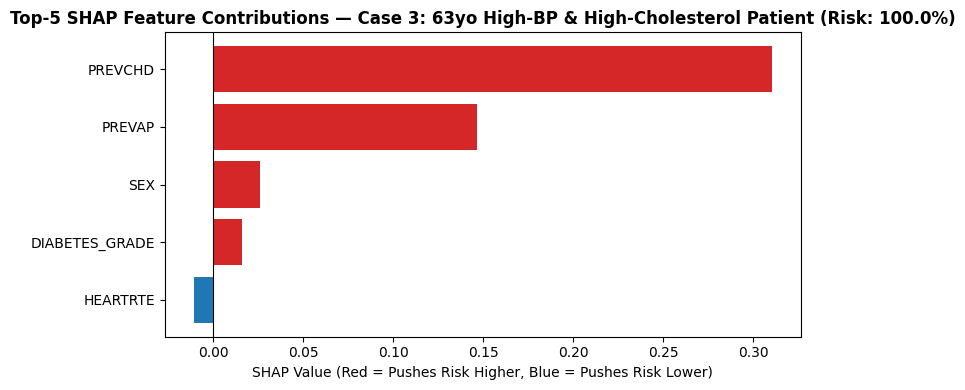

In [2]:
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

MODEL_PATH = "/content/saved_models/chd_rf_best_model.pkl"
SCALER_PATH = "/content/saved_models/minmax_scaler.pkl"
FEATURES_PATH = "/content/saved_models/feature_columns.pkl"

model = joblib.load(MODEL_PATH)
scaler = joblib.load(SCALER_PATH)
features = joblib.load(FEATURES_PATH)

print("Loaded Model, Scaler, and Features Successfully!\n")

def get_diabetes_grade(glucose):
    if glucose < 100:
        return 1
    elif glucose < 126:
        return 2
    elif glucose < 200:
        return 3
    else:
        return 4

def generate_recommendations(patient, risk_band):
    advice = []
    if patient["SYSBP"] >= 140 or patient["DIABP"] >= 90:
        advice.append("Blood Pressure: Follow DASH diet (<2g sodium/day) and monitor BP twice daily.")
    if patient["TOTCHOL"] >= 240:
        advice.append("Cholesterol: Reduce saturated/trans fats and schedule a complete lipid profile test.")
    if patient["CIGPDAY"] > 0:
        advice.append("Smoking Cessation: Quit smoking immediately to lower CHD risk within 1 year.")
    if patient["BMI"] >= 25.0:
        advice.append("Weight Management: Engage in 150 mins/week of brisk aerobic exercise to target BMI < 25.")
    if patient["GLUCOSE"] >= 126:
        advice.append("Blood Sugar: Restrict refined carbohydrates and monitor HbA1c every 3 months.")
    if risk_band == "HIGH RISK":
        advice.append("URGENT MEDICAL ACTION: Consult a cardiologist immediately for an ECG and Stress Echo test.")
    if not advice:
        advice.append("Lifestyle Maintenance: Parameters are within normal range. Continue balanced diet and annual checkups.")
    return advice

def test_single_patient(patient_data, patient_name="Test Patient", show_shap=True):
    patient_data["PULSE_PRESSURE"] = patient_data["SYSBP"] - patient_data["DIABP"]
    patient_data["DIABETES_GRADE"] = get_diabetes_grade(patient_data["GLUCOSE"])

    df_input = pd.DataFrame([patient_data])[features]
    df_scaled = pd.DataFrame(scaler.transform(df_input), columns=features)

    pred_class = model.predict(df_scaled)[0]
    pred_prob = model.predict_proba(df_scaled)[0][1] * 100

    if pred_prob >= 60:
        risk_band = "HIGH RISK"
    elif pred_prob >= 30:
        risk_band = "MODERATE RISK"
    else:
        risk_band = "LOW RISK"

    print("=" * 65)
    print(f"PATIENT REPORT : {patient_name}")
    print("=" * 65)
    print(f"Predicted Class : {'CHD POSITIVE (1)' if pred_class == 1 else 'HEALTHY / NO CHD (0)'}")
    print(f"CHD Risk Score  : {pred_prob:.2f}%  -->  [{risk_band}]")

    explainer = shap.TreeExplainer(model)
    shap_vals = explainer.shap_values(df_scaled)
    patient_shap = shap_vals[1][0] if isinstance(shap_vals, list) else shap_vals[0, :, 1]

    shap_series = pd.Series(patient_shap, index=features)
    top_5 = shap_series.abs().sort_values(ascending=False).head(5).index

    print("\nTop 5 Contributing Clinical Factors (SHAP Explainability):")
    for rank, col in enumerate(top_5, 1):
        impact = shap_series[col]
        direction = "Increases Risk (+)" if impact > 0 else "Reduces Risk (-)"
        print(f"  {rank}. {col:<16} = {patient_data[col]:<6} | SHAP Impact: {impact:+.4f} ({direction})")

    print("\nPersonalized Preventive Recommendations:")
    for item in generate_recommendations(patient_data, risk_band):
        print(f"  * {item}")
    print("=" * 65 + "\n")

    if show_shap:
        plt.figure(figsize=(8, 4))
        colors = ["#d62728" if shap_series[c] > 0 else "#1f77b4" for c in top_5[::-1]]
        plt.barh(top_5[::-1], [shap_series[c] for c in top_5[::-1]], color=colors)
        plt.axvline(0, color="black", linewidth=0.8)
        plt.title(f"Top-5 SHAP Feature Contributions — {patient_name} (Risk: {pred_prob:.1f}%)", fontweight="bold")
        plt.xlabel("SHAP Value (Red = Pushes Risk Higher, Blue = Pushes Risk Lower)")
        plt.tight_layout()
        plt.show()

low_risk_patient = {
    "SEX": 2, "AGE": 38, "TOTCHOL": 182.0, "SYSBP": 115.0, "DIABP": 74.0,
    "CIGPDAY": 0.0, "BMI": 22.4, "BPMEDS": 0.0, "HEARTRTE": 70.0,
    "GLUCOSE": 84.0, "PREVCHD": 0, "PREVAP": 0, "PREVMI": 0, "PREVHYP": 0
}

moderate_risk_patient = {
    "SEX": 1, "AGE": 52, "TOTCHOL": 238.0, "SYSBP": 138.0, "DIABP": 88.0,
    "CIGPDAY": 10.0, "BMI": 27.1, "BPMEDS": 0.0, "HEARTRTE": 78.0,
    "GLUCOSE": 108.0, "PREVCHD": 0, "PREVAP": 0, "PREVMI": 0, "PREVHYP": 1
}

high_risk_patient = {
    "SEX": 1, "AGE": 63, "TOTCHOL": 285.0, "SYSBP": 164.0, "DIABP": 98.0,
    "CIGPDAY": 25.0, "BMI": 31.2, "BPMEDS": 1.0, "HEARTRTE": 88.0,
    "GLUCOSE": 162.0, "PREVCHD": 1, "PREVAP": 1, "PREVMI": 0, "PREVHYP": 1
}

test_single_patient(low_risk_patient, patient_name="Case 1: 38yo Healthy Non-Smoker", show_shap=False)
test_single_patient(moderate_risk_patient, patient_name="Case 2: 52yo Borderline Smoker", show_shap=False)
test_single_patient(high_risk_patient, patient_name="Case 3: 63yo High-BP & High-Cholesterol Patient", show_shap=True)

In [4]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "n_estimators": [100, 200],      # Kitne Decision Trees banane hain
    "max_depth": [15, 20, None],     # Har Decision Tree ki maximum gehrai (depth)
    "min_samples_split": [2, 5],     # Node split karne ke liye minimum patients
    "criterion": ["gini", "entropy"] # Decision Tree ka split formula
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,               # 5-Fold Cross Validation
    scoring="recall",   # Healthcare mein Recall maximize karne ke liye
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)
print("Best Parameters from GridSearchCV:", grid_search.best_params_)

Best Parameters from GridSearchCV: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
